# 반도체 수율·불량 예측: 누수 방지 분석

공식 UCI SECOM 데이터의 수율을 계산하고, 학습·검증·테스트를 분리해 불량 예측 모델을 평가합니다. 실행 방법과 해석상 한계는 [README](README.md)를 참고하세요.

**선택 원칙:** 학습 데이터 안에서만 전처리·교차검증 → 검증 데이터로 임계값 고정 → 테스트 평가. 이 테스트 분할은 과거 분석에서도 살펴본 데이터이며 새로운 외부 검증은 아닙니다.

In [1]:
from pathlib import Path
import os

for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(variable, '1')

import pandas as pd
from IPython.display import Image, display
from secom_analysis import load_secom, split_indices, make_pipeline, run_analysis

project_dir = Path.cwd()
assert (project_dir / 'secom_analysis.py').is_file(), '저장소 루트에서 실행하세요.'
data_dir = Path(os.environ.get('SECOM_DATA_DIR', project_dir / 'data'))
output_dir = project_dir / 'results'


## 1. 데이터와 수율

첫 실행은 공식 UCI ZIP을 내려받습니다. 다운로드와 캐시 모두 SHA-256을 검증합니다. 센서 590개와 라벨·시간 정보가 있으며, 불량 라벨 1은 그대로 두고 정상 -1을 0으로 변환합니다. 데이터 파일은 Git에 포함하지 않습니다.

In [2]:
X, y, timestamps = load_secom(data_dir)
display(pd.DataFrame({
    '항목': ['전체 샘플', '센서 수', '불량 수', '정상 수', '불량률', '수율'],
    '값': [len(y), X.shape[1], int(y.sum()), int((y == 0).sum()),
           f'{y.mean():.4%}', f'{(y == 0).mean():.4%}'],
}))

,항목,값
0,전체 샘플,1567
1,센서 수,590
2,불량 수,104
3,정상 수,1463
4,불량률,6.6369%
5,수율,93.3631%


## 2. 먼저 분할하고, 학습 데이터로만 전처리

random_state=42의 계층화 분할로 약 60% 학습, 20% 검증, 20% 테스트를 만듭니다. 테스트를 먼저 20% 분리하고 나머지의 25%를 검증용으로 사용합니다.

각 CV 학습 fold에서 결측률 40% 초과 센서 제거 → 중앙값 대체 → 분산 0.05 이하 센서 제거 → 표준화 → SMOTE → XGBoost 순서로 학습합니다. SMOTE의 거리 계산 전에 표준화하며, 추론에는 SMOTE를 적용하지 않습니다. 추가 클래스 가중치는 1로 고정합니다.

In [3]:
splits = split_indices(y)
display(pd.DataFrame({name: {
    'samples': len(indices), 'defects': int(y.iloc[indices].sum())
} for name, indices in splits.items()}).T)
make_pipeline()

,samples,defects
train,939,62
validation,314,21
test,314,21


,steps,"[('missing', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,max_missing_rate,0.4
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


## 3. 모델 탐색과 임계값 선택

학습 데이터의 3-fold CV에서 평균 정밀도(AP)가 가장 높은 모델을 고릅니다. max_depth 3개 × learning_rate 3개 × n_estimators 3개 = 27개 조합, 총 81회 CV 학습입니다. AP는 특정 분류 임계값에 의존하지 않습니다.

선택된 모델은 학습 분할에만 재학습합니다. 검증 확률의 고유 값 중 불량 F1을 최대화하는 임계값을 고르고, F1이 정확히 같으면 높은 임계값을 선택합니다. 판정 규칙은 `확률 >= 임계값`입니다. 이후 모델이나 임계값을 재학습·재선택하지 않고 테스트를 평가합니다.

In [4]:
report = run_analysis(data_dir=data_dir, output_dir=output_dir, jobs=2)
print('최적 파라미터:', report['search']['best_parameters'])
print('최고 CV AP:', report['search']['best_cv_average_precision'])
print('검증 데이터로 선택한 임계값:', report['threshold_selection']['threshold'])
print('검증 F1:', report['threshold_selection']['validation_f1'])
print('선택된 센서 수:', report['preprocessing']['selected_features'])

Fitting 3 folds for each of 27 candidates, totalling 81 fits


최적 파라미터: {'xgb__learning_rate': 0.01, 'xgb__max_depth': 5, 'xgb__n_estimators': 200}
최고 CV AP: 0.24458092459237948
검증 데이터로 선택한 임계값: 0.41138148307800293
검증 F1: 0.2352941176470588
선택된 센서 수: 264


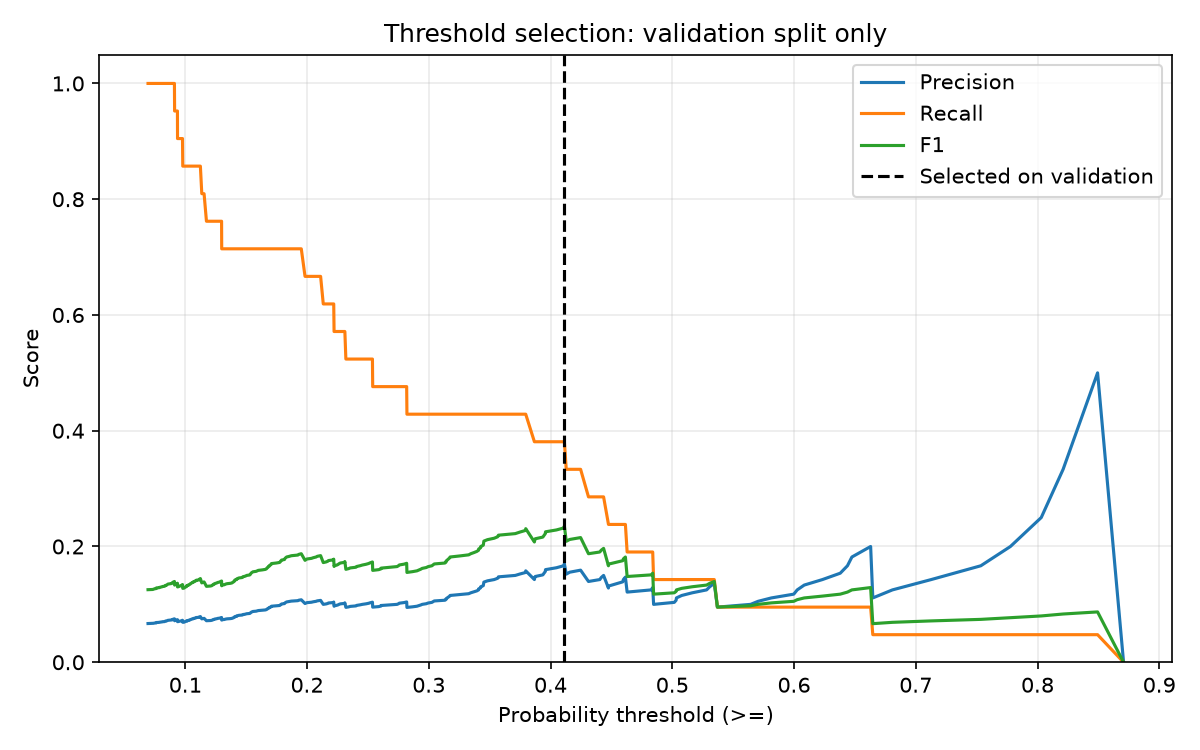

In [5]:
display(Image(filename=str(output_dir / 'validation_threshold.png')))

## 4. 고정된 규칙으로 테스트 평가

기본 임계값 0.5와 검증 데이터에서 고정한 임계값을 함께 보고합니다. 아래 테스트 지표를 보고 임계값이나 모델을 다시 선택하지 않습니다. 모든 예측은 파이프라인에 원본 센서 값을 전달하므로 스케일링이 중복되지 않습니다.

,임계값,불량 정밀도,불량 재현율,불량 F1,정확도
설정,,,,,
기본 0.5,0.500000,0.190476,0.190476,0.190476,0.891720
검증 F1 선택,0.411381,0.131579,0.238095,0.169492,0.843949


테스트 AP: 0.12700002541279665
테스트 ROC-AUC: 0.6874695270599708


,precision,recall,f1-score,support
0,0.942029,0.887372,0.913884,293.000000
1,0.131579,0.238095,0.169492,21.000000
accuracy,0.843949,0.843949,0.843949,0.843949
macro avg,0.536804,0.562734,0.541688,314.000000
weighted avg,0.887827,0.843949,0.864100,314.000000


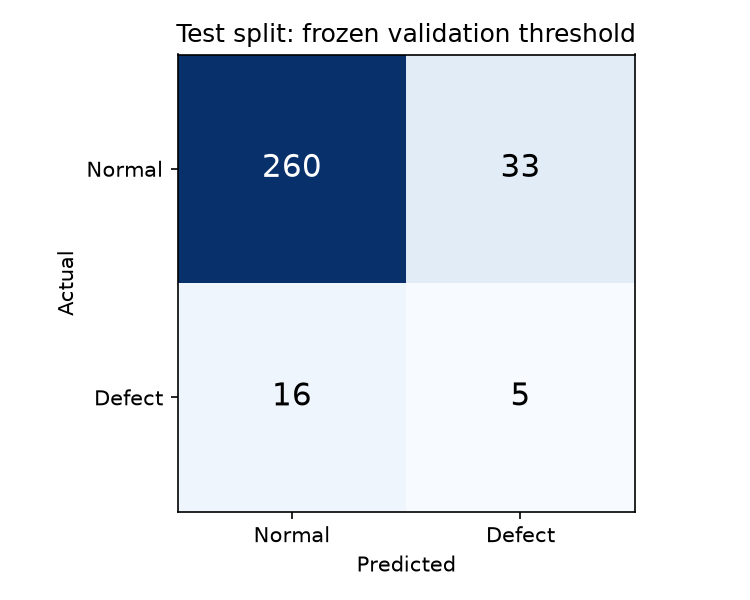

In [6]:
rows = []
for name, key in [('기본 0.5', 'test_default_threshold'), ('검증 F1 선택', 'test_selected_threshold')]:
    result = report[key]
    defect = result['classification_report']['1']
    rows.append({
        '설정': name, '임계값': result['threshold'],
        '불량 정밀도': defect['precision'], '불량 재현율': defect['recall'],
        '불량 F1': defect['f1-score'], '정확도': result['classification_report']['accuracy'],
    })
display(pd.DataFrame(rows).set_index('설정'))
print('테스트 AP:', report['test_average_precision'])
print('테스트 ROC-AUC:', report['test_roc_auc'])
display(pd.DataFrame(report['test_selected_threshold']['classification_report']).T)
display(Image(filename=str(output_dir / 'test_confusion_matrix.png')))

## 5. 해석과 한계

- 검증·테스트에는 불량이 각각 21건뿐입니다. 임계값과 성능 수치의 불확실성이 큽니다.
- 테스트 분할은 이전의 잘못된 분석에서도 이미 열람했습니다. 이번 코드는 테스트를 선택에 사용하지 않지만, 이를 완전히 새로운 외부 검증으로 설명할 수 없습니다.
- 무작위 계층화 분할은 미래 생산 시점·배치 효과·공정 변화를 검증하지 않습니다.
- 검증 F1 최대화는 공개된 선택 기준이며, 실제 불량 누락 비용과 오탐 비용을 반영한 사업상 최적값은 아닙니다.
- 분산 임계값 0.05는 원래 센서 단위에 의존하는 고정 기준입니다. 임의 단위의 센서에 일반적으로 최적인 기준이라고 주장하지 않습니다.

실행 결과는 `results/metrics.json`, 전체 CV 결과, 검증·테스트 예측 CSV와 그래프에 저장됩니다. 이전의 이중 스케일링 결과와 테스트에서 고른 임계값 성능은 현재 결과로 사용하지 않습니다.

이번 실행에서 검증 임계값의 테스트 불량 F1은 0.1695로, 기본 0.5의 0.1905보다 낮았습니다. 불량 1건을 더 탐지했지만 정상 오탐이 17건에서 33건으로 늘었습니다. 이 결과를 보고 임계값을 다시 고르지 않았습니다.